Accuracy Score: 0.9736842105263158

Confusion Matrix :
 [[41  2]
 [ 1 70]]

Classification Report :
               precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



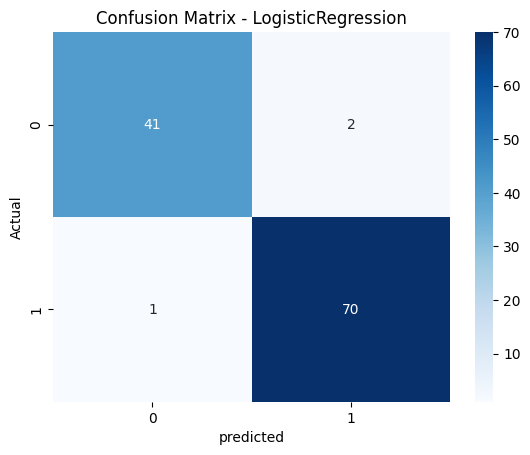

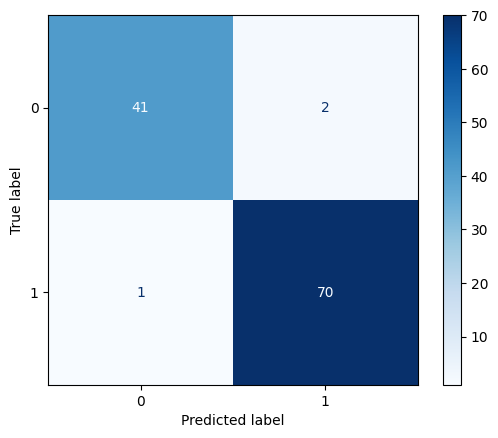

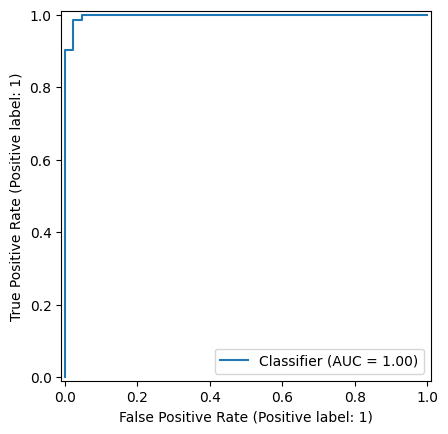

In [ ]:
from sklearn.compose import ColumnTransformer
# import libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score,roc_curve
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_breast_cancer
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report
from sklearn.metrics import ConfusionMatrixDisplay,RocCurveDisplay



# loading data set
data=load_breast_cancer(as_frame=True)
df=data.frame
df.head()

# assigning x and y

x=df.drop('target',axis=1)
y=df['target']

# splitting
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

scaler=StandardScaler()
mod_pipeline=Pipeline(steps=[
    ('scaler',StandardScaler()),
    ('Model',LogisticRegression(random_state=42))
])
mod_pipeline.fit(x_train,y_train)
y_pred=mod_pipeline.predict(x_test)

y_proba=mod_pipeline.predict_proba(x_test)[:,1]

print('Accuracy Score:',accuracy_score(y_test,y_pred))
print('\nConfusion Matrix :\n',confusion_matrix(y_test,y_pred))
print('\nClassification Report :\n',classification_report(y_test,y_pred))

# confusion matrix heatmap
cm=confusion_matrix(y_test,y_pred)
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.xlabel('predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix - LogisticRegression')
plt.savefig('confusion matrix.png')
plt.show()

ConfusionMatrixDisplay.from_predictions(y_test,y_pred,cmap='Blues')
plt.savefig('confusion_matrix.png')
plt.show()

RocCurveDisplay.from_predictions(y_test,y_proba)
plt.show()

In [ ]:
model=LogisticRegression()
model.get_params()

{'C': 1.0,
 'class_weight': None,
 'dual': False,
 'fit_intercept': True,
 'intercept_scaling': 1,
 'l1_ratio': None,
 'max_iter': 100,
 'multi_class': 'deprecated',
 'n_jobs': None,
 'penalty': 'l2',
 'random_state': None,
 'solver': 'lbfgs',
 'tol': 0.0001,
 'verbose': 0,
 'warm_start': False}

              precision    recall  f1-score   support

           0       0.98      0.95      0.96        43
           1       0.97      0.99      0.98        71

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



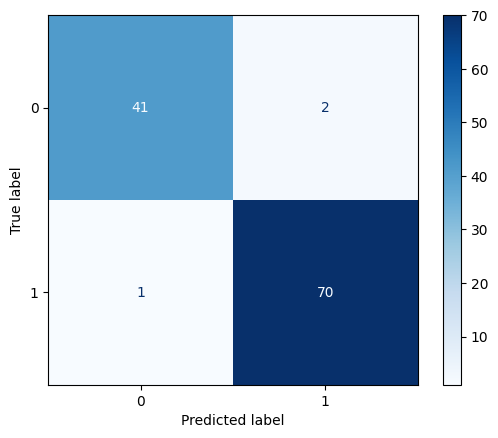

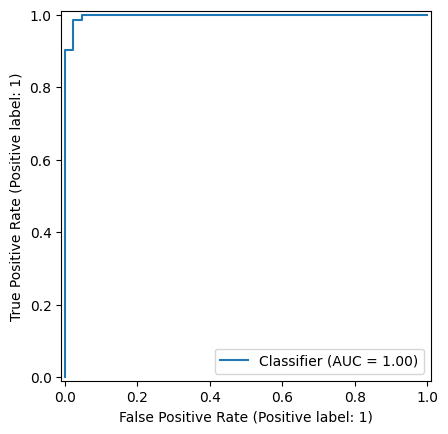

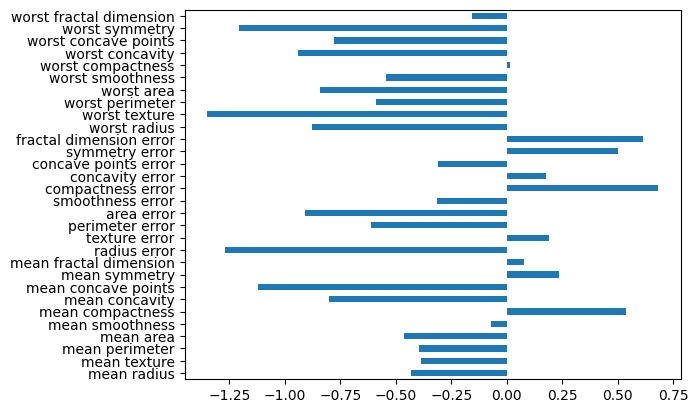

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    classification_report,
)

# --- 1. MODEL TRAINING & PREDICTIONS ---
mod_pipeline.fit(x_train, y_train)
y_pred = mod_pipeline.predict(x_test)
y_proba = mod_pipeline.predict_proba(x_test)[
    :, 1
]  # ROC curve ke liye probability score

# --- 2. TEXT REPORTS ---
print(classification_report(y_test, y_pred))

# --- 3. PLOTS (Sirf 2-2 Lines Me!) ---

# Plot 1: Confusion Matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.savefig("confusion_matrix.png")
plt.show()

# Plot 2: ROC Curve (Yeh khud hi AUC score nikal lega)
RocCurveDisplay.from_predictions(y_test, y_proba)
plt.savefig("roc_curve.png")
plt.show()

# Plot 3: Feature Importance (Weights -> Column Names -> Horizontal Bar)
pd.Series(mod_pipeline.named_steps["Model"].coef_[0], index=x.columns).plot(
    kind="barh"
)
plt.savefig("feature_importance.png")
plt.show()


In [ ]:
data=load_breast_cancer(as_frame=True)
df=data.frame
df.head(4)

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0


In [1]:


# loading libraries
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import load_breast_cancer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold,cross_validate

# loading dataset
data=load_breast_cancer(as_frame=True)
df=data.frame
df.head()

# EDA and basic inspection of data
df.isnull().sum()
df.duplicated().sum()
df.shape

# defining x and y
x=df.drop('target',axis=1)
y=df['target']

#  spliting
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

# preprocessing
preprocessing=Pipeline(steps=[
    ('preprocessing',StandardScaler()),
    ('Model',LogisticRegression(max_iter=1000,n_jobs=None,l1_ratio=None,random_state=42))
])

# fit transorm
preprocessing.fit(x_train,y_train)
y_predict=preprocessing.predict(x_test)

# Evaluation
print('Accuracy Score:',accuracy_score(y_test,y_predict))

cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=42)
print(cv)

from sklearn.model_selection import cross_validate

scoring=['accuracy','precision','recall','f1','roc_auc']
results=cross_validate(preprocessing,x,y,cv=cv,scoring=scoring)
print(results)

import numpy as np

# Model 1: default (C=1.0) -> tumhara existing `results`
# Model 2: strong regularization
model_strong = Pipeline(steps=[
    ('scaler', StandardScaler()),
    ('Model', LogisticRegression(C=0.001, max_iter=1000, random_state=42))
])
results_strong = cross_validate(model_strong, x, y, cv=cv, scoring=scoring)

# Comparison table (mean ± std)
rows = []
for m in scoring:
    r1 = results['test_' + m]
    r2 = results_strong['test_' + m]
    rows.append({
        'Metric': m,
        'Default (C=1.0)': f"{r1.mean():.4f} ± {r1.std():.4f}",
        'Strong Reg (C=0.001)': f"{r2.mean():.4f} ± {r2.std():.4f}"
    })

comparison = pd.DataFrame(rows)
comparison






Accuracy Score: 0.9736842105263158
StratifiedKFold(n_splits=5, random_state=42, shuffle=True)
{'fit_time': array([0.08683848, 0.0420506 , 0.01616192, 0.02252555, 0.04933786]), 'score_time': array([0.06012297, 0.05853343, 0.02157283, 0.06837869, 0.07214785]), 'test_accuracy': array([0.97368421, 0.94736842, 0.96491228, 0.99122807, 0.99115044]), 'test_precision': array([0.98571429, 0.92207792, 0.94736842, 1.        , 0.98611111]), 'test_recall': array([0.97183099, 1.        , 1.        , 0.98611111, 1.        ]), 'test_f1': array([0.9787234 , 0.95945946, 0.97297297, 0.99300699, 0.99300699]), 'test_roc_auc': array([0.9950868 , 0.99770717, 0.98511905, 1.        , 0.99865862])}


,Metric,Default (C=1.0),Strong Reg (C=0.001)
0,accuracy,0.9737 ± 0.0166,0.8946 ± 0.0318
1,precision,0.9683 ± 0.0290,0.8605 ± 0.0324
2,recall,0.9916 ± 0.0112,0.9944 ± 0.0113
3,f1,0.9794 ± 0.0127,0.9224 ± 0.0225
4,roc_auc,0.9953 ± 0.0053,0.9877 ± 0.0060


## Conclusion: Which Model Should Be Deployed?

I compared two Logistic Regression pipelines using 5-fold Stratified Cross-Validation on the Breast Cancer dataset: the default model (C=1.0) and a heavily regularized model (C=0.001).

| Metric | Default (C=1.0) | Strong Reg (C=0.001) |
|---|---|---|
| Accuracy | 0.9737 ± 0.0166 | 0.8946 ± 0.0318 |
| Precision | 0.9683 ± 0.0290 | 0.8605 ± 0.0324 |
| Recall | 0.9916 ± 0.0112 | 0.9944 ± 0.0113 |
| F1 | 0.9794 ± 0.0127 | 0.9224 ± 0.0225 |
| ROC-AUC | 0.9953 ± 0.0053 | 0.9877 ± 0.0060 |

**Decision: I would deploy the default model (C=1.0).**

**Reasons:**
- It is clearly better on accuracy (97.4% vs 89.5%), precision (96.8% vs 86.0%), F1 (0.979 vs 0.922) and ROC-AUC (0.995 vs 0.988).
- Recall is almost the same for both (99.2% vs 99.4%). The gap is smaller than the standard deviation (about 0.011), so it is not a meaningful difference.
- With C=0.001 the model is over-regularized (underfitting). It labels too many cases as positive, so precision drops by about 11 points, which means many false alarms.
- The default model also has lower variance across folds (std 0.0166 vs 0.0318 on accuracy), so its results are more stable.

**Conclusion:** Strong regularization does not help here. The default model gives the same recall with far fewer false positives, so it is the better choice for deployment.